ИНФОРМАЦИЯ ОБ ЭКСПЕРИМЕНТЕ
Исходный файл: C:\Users\мирон\Desktop\laba po pitonu\data\raw\source.csv
Размер файла: 5433.25 МБ
Python: 3.12.10
pandas: 3.0.6
Polars: 2.0.0
Логических процессоров: 12
Оперативная память: 15.63 ГБ
Доступная память: 7.26 ГБ

PANDAS
Строк исходного файла: 55,423,856
Чтение: 41.991 сек.
Обработка: 0.608 сек.
Общее время: 42.599 сек.
Память DataFrame: 845.70 МБ
Строк после фильтрации: 5,675,820
 passenger_count  median_fare    passenger_group
               9        95.00 Другое / проверить
               8        80.00 Другое / проверить
               7        70.00 Другое / проверить
             208        45.30 Другое / проверить
               2        30.83        2 пассажира
               6        30.50       6 пассажиров
               4        30.50        4 пассажира
               3        30.10        3 пассажира
               5        30.00       5 пассажиров
               1        29.70         1 пассажир
               0        26.50         Н

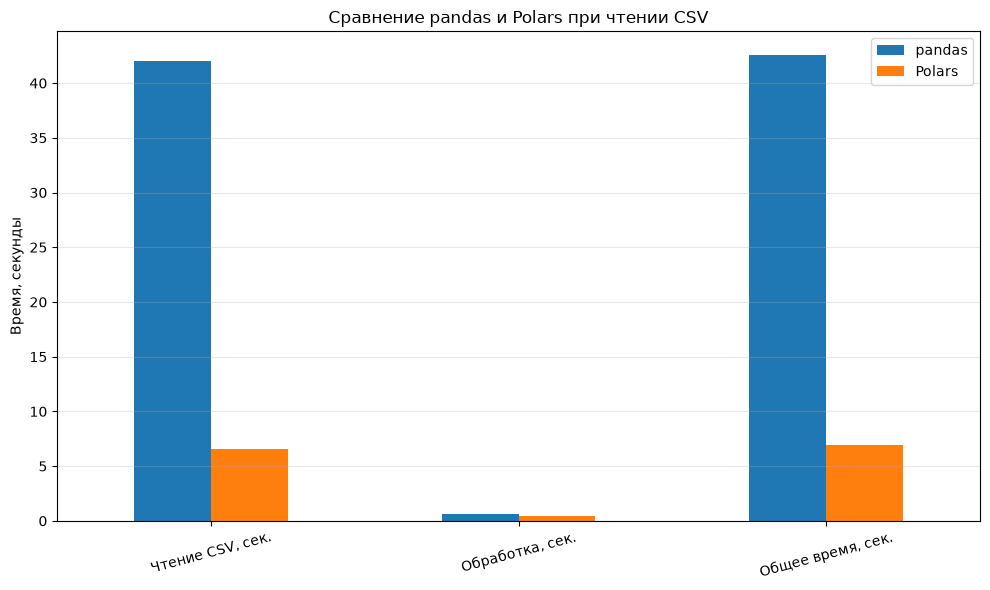


Все результаты сохранены в: E:\laba_results


In [4]:
from pathlib import Path
import time
import os
import gc
import platform
import psutil
import pandas as pd
import polars as pl
import matplotlib.pyplot as plt

# =====================================================
# 1. НАСТРОЙКИ
# =====================================================
SOURCE_PATH = Path(
    r"C:\Users\мирон\Desktop\laba po pitonu\data\raw\source.csv"
)
RESULTS_DIR = Path(r"E:\laba_results")
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

FARE_LIMIT = 20
COLUMNS = ["fare_amount", "passenger_count"]

if not SOURCE_PATH.exists():
    raise FileNotFoundError(
        f"Файл не найден: {SOURCE_PATH}. Проверь путь к source.csv."
    )

# Справочная таблица для JOIN
labels = pd.DataFrame({
    "passenger_count": [0, 1, 2, 3, 4, 5, 6],
    "passenger_group": [
        "Не указано", "1 пассажир", "2 пассажира",
        "3 пассажира", "4 пассажира", "5 пассажиров",
        "6 пассажиров"
    ]
})
labels_pl = pl.from_pandas(labels)

# =====================================================
# 2. ИНФОРМАЦИЯ ОБ ЭКСПЕРИМЕНТЕ
# =====================================================
memory = psutil.virtual_memory()

print("=" * 60)
print("ИНФОРМАЦИЯ ОБ ЭКСПЕРИМЕНТЕ")
print("=" * 60)
print("Исходный файл:", SOURCE_PATH)
print(f"Размер файла: {SOURCE_PATH.stat().st_size / 1024**2:.2f} МБ")
print("Python:", platform.python_version())
print("pandas:", pd.__version__)
print("Polars:", pl.__version__)
print("Логических процессоров:", os.cpu_count())
print(f"Оперативная память: {memory.total / 1024**3:.2f} ГБ")
print(f"Доступная память: {memory.available / 1024**3:.2f} ГБ")

# =====================================================
# 3. PANDAS
# =====================================================
print("\n" + "=" * 60)
print("PANDAS")
print("=" * 60)

start = time.perf_counter()
df_pd = pd.read_csv(SOURCE_PATH, usecols=COLUMNS)
pd_read_time = time.perf_counter() - start

df_pd["fare_amount"] = pd.to_numeric(
    df_pd["fare_amount"], errors="coerce"
)
df_pd["passenger_count"] = pd.to_numeric(
    df_pd["passenger_count"], errors="coerce"
)

pd_memory = df_pd.memory_usage(deep=True).sum() / 1024**2

start = time.perf_counter()
filtered_pd = df_pd[df_pd["fare_amount"] > FARE_LIMIT]

pd_rows = len(filtered_pd)

result_pd = (
    filtered_pd.groupby("passenger_count", dropna=False)["fare_amount"]
    .median()
    .reset_index(name="median_fare")
    .sort_values("median_fare", ascending=False)
)

result_pd["passenger_count"] = result_pd["passenger_count"].astype("Int64")
result_pd = result_pd.merge(labels, on="passenger_count", how="left")
result_pd["passenger_group"] = result_pd["passenger_group"].fillna(
    "Другое / проверить"
)

pd_process_time = time.perf_counter() - start
pd_total_time = pd_read_time + pd_process_time

print(f"Строк исходного файла: {len(df_pd):,}")
print(f"Чтение: {pd_read_time:.3f} сек.")
print(f"Обработка: {pd_process_time:.3f} сек.")
print(f"Общее время: {pd_total_time:.3f} сек.")
print(f"Память DataFrame: {pd_memory:.2f} МБ")
print(f"Строк после фильтрации: {pd_rows:,}")
print(result_pd.to_string(index=False))

result_pd.to_csv(
    RESULTS_DIR / "step11_pandas_result.csv",
    index=False,
    encoding="utf-8-sig"
)

del df_pd, filtered_pd
gc.collect()

# =====================================================
# 4. POLARS
# =====================================================
print("\n" + "=" * 60)
print("POLARS")
print("=" * 60)

start = time.perf_counter()
df_pl = pl.read_csv(
    SOURCE_PATH,
    columns=COLUMNS,
    infer_schema_length=10000
).with_columns(
    pl.col("fare_amount").cast(pl.Float64, strict=False),
    pl.col("passenger_count").cast(pl.Int64, strict=False)
)
pl_read_time = time.perf_counter() - start

pl_memory = df_pl.estimated_size("mb")

start = time.perf_counter()
filtered_pl = df_pl.filter(pl.col("fare_amount") > FARE_LIMIT)
pl_rows = filtered_pl.height

result_pl = (
    filtered_pl
    .group_by("passenger_count")
    .agg(pl.col("fare_amount").median().alias("median_fare"))
    .sort("median_fare", descending=True)
    .join(labels_pl, on="passenger_count", how="left")
    .with_columns(
        pl.col("passenger_group").fill_null("Другое / проверить")
    )
)

pl_process_time = time.perf_counter() - start
pl_total_time = pl_read_time + pl_process_time

print(f"Строк исходного файла: {df_pl.height:,}")
print(f"Чтение: {pl_read_time:.3f} сек.")
print(f"Обработка: {pl_process_time:.3f} сек.")
print(f"Общее время: {pl_total_time:.3f} сек.")
print(f"Память DataFrame: {pl_memory:.2f} МБ")
print(f"Строк после фильтрации: {pl_rows:,}")
print(result_pl)

result_pl.write_csv(RESULTS_DIR / "step11_polars_result.csv")

del df_pl, filtered_pl
gc.collect()

# =====================================================
# 5. POLARS LAZY
# =====================================================
print("\n" + "=" * 60)
print("POLARS LAZY")
print("=" * 60)

start = time.perf_counter()

result_lazy = (
    pl.scan_csv(SOURCE_PATH, infer_schema_length=10000)
    .select([
        pl.col("fare_amount").cast(pl.Float64, strict=False),
        pl.col("passenger_count").cast(pl.Int64, strict=False)
    ])
    .filter(pl.col("fare_amount") > FARE_LIMIT)
    .group_by("passenger_count")
    .agg(pl.col("fare_amount").median().alias("median_fare"))
    .sort("median_fare", descending=True)
    .join(labels_pl.lazy(), on="passenger_count", how="left")
    .with_columns(
        pl.col("passenger_group").fill_null("Другое / проверить")
    )
    .collect()
)

lazy_time = time.perf_counter() - start

print(f"Общее время цепочки Lazy: {lazy_time:.3f} сек.")
print("Время включает чтение, фильтрацию и все операции.")
print(result_lazy)

result_lazy.write_csv(RESULTS_DIR / "step11_polars_lazy_result.csv")

# =====================================================
# 6. ПРОВЕРКА РЕЗУЛЬТАТОВ
# =====================================================
def normalize_pandas(df):
    out = df[["passenger_count", "median_fare"]].copy()
    out["passenger_count"] = pd.to_numeric(
        out["passenger_count"], errors="coerce"
    ).astype("Int64")
    out["median_fare"] = pd.to_numeric(
        out["median_fare"], errors="coerce"
    ).round(8)
    return out.sort_values(
        "passenger_count", na_position="last"
    ).reset_index(drop=True)

def normalize_polars(df):
    return normalize_pandas(df.select(
        ["passenger_count", "median_fare"]
    ).to_pandas())

same_pl = normalize_pandas(result_pd).equals(
    normalize_polars(result_pl)
)
same_lazy = normalize_pandas(result_pd).equals(
    normalize_polars(result_lazy)
)

print("\n" + "=" * 60)
print("ПРОВЕРКА РЕЗУЛЬТАТОВ")
print("=" * 60)
print("pandas и Polars совпадают:", same_pl)
print("pandas и Polars Lazy совпадают:", same_lazy)

# =====================================================
# 7. ИТОГОВАЯ ТАБЛИЦА
# =====================================================
summary = pd.DataFrame([
    ["Чтение CSV, сек.", pd_read_time, pl_read_time],
    ["Обработка, сек.", pd_process_time, pl_process_time],
    ["Общее время, сек.", pd_total_time, pl_total_time],
    ["Размер DataFrame, МБ", pd_memory, pl_memory]
], columns=["Показатель", "pandas", "Polars"])

summary["Ускорение Polars относительно pandas"] = (
    summary["pandas"] / summary["Polars"]
)
summary.loc[
    summary["Показатель"] == "Размер DataFrame, МБ",
    "Ускорение Polars относительно pandas"
] = float("nan")

print("\n" + "=" * 60)
print("ТАБЛИЦА ДЛЯ ОТЧЁТА")
print("=" * 60)
print(summary.round(3).to_string(index=False))
print(f"\nОбщее время Polars Lazy: {lazy_time:.3f} сек.")

summary.to_csv(
    RESULTS_DIR / "step11_summary.csv",
    index=False,
    encoding="utf-8-sig"
)

# =====================================================
# 8. ДИАГРАММА
# =====================================================
chart_data = summary.iloc[:3].set_index("Показатель")[
    ["pandas", "Polars"]
]

ax = chart_data.plot(kind="bar", figsize=(10, 6))
ax.set_title("Сравнение pandas и Polars при чтении CSV")
ax.set_ylabel("Время, секунды")
ax.set_xlabel("")
ax.tick_params(axis="x", rotation=15)
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.savefig(RESULTS_DIR / "step11_comparison.png", dpi=150)
plt.show()

print("\nВсе результаты сохранены в:", RESULTS_DIR)